### Dylan Renard
### Applied Machine Learning JHU
### Homework 9
### Professor Alhassan
### March 28th, 2026

## HW Assignment 9: Applied Machine Learning @
Please refer to Reinforcement Learning Jupyter notebook in course materials. Answer questions 1-3 considering any Nim game reinforcement learning model.

#### Q1: Describe the environment in the Nim learning model.

The environment in the Nim learning model is defined by the current state of the game, which consists of the number of items remaining in each pile. Each state is fully observable, meaning the agent has complete information about the system at every step. When the agent takes an action (removing a selected number of items from a pile), the environment transitions deterministically to a new state based on that action. The game is episodic, as each sequence of interactions ends when all piles are empty.

This setup aligns with the reinforcement learning framework described in the textbook, where an agent interacts with an environment through states, actions, and transitions over time to learn optimal behavior (Raschka et al., 2022).

#### Q2: Describe the agent(s) in the Nim learning model (Hint, not just the Q-learner). Is Guru an agent?

The Nim learning model includes multiple agents that interact within the environment. The primary agent is the Q-learning agent, which learns a policy by updating Q-values based on its experiences. This agent selects actions in order to maximize long-term rewards.

In addition to the Q-learner, the opponent in the game is also an agent. This opponent may follow a random strategy or a predefined heuristic strategy. The “Guru” player is considered an agent as well, since it interacts with the environment by selecting actions based on an optimal or near-optimal strategy. Although the Guru does not learn through reinforcement, it still functions as an agent because it makes decisions that influence state transitions.

#### Q3: Describe the reward and penalty in the Nim learning model.

The reward structure in the Nim learning model is sparse and primarily outcome-based. A positive reward is assigned when the Q-learning agent wins the game, while a negative reward (penalty) is given when the agent loses. For most intermediate states, the reward is typically zero, meaning the agent does not receive feedback until the end of the episode.

This setup reflects a common reinforcement learning approach where agents learn by maximizing cumulative reward over time rather than receiving immediate feedback at every step. Because rewards are delayed until the terminal state, the agent must learn which sequences of actions lead to successful outcomes through repeated interactions (Raschka et al., 2022).

#### Q4: How many possible states there could be in the Nim game with a maximum of 10 items per pile and 3 piles total? (this problem requires a number for its answer, not merely a closed-form expression.)

Each of the 3 piles can contain between 0 and 10 items, inclusive. This gives 11 possible values per pile (0 through 10). Since the piles are independent, the total number of possible states is:

11 * 11 * 11 = 1331

Therefore, there are 1331 possible states in the Nim game.

#### Q5: How many possible unique actions are there for player 1 to take as their first action in a Nim game with 10 items per pile and 3 piles total? (This problem also requires a number for its answer, not merely a closed-form expression.)

At the start of the game, each of the 3 piles contains 10 items. A valid action consists of selecting one pile and removing between 1 and 10 items from that pile.

For each pile, there are 10 possible actions (removing 1 through 10 items). Since there are 3 piles, the total number of unique first actions is:

3 * 10 = 30

Therefore, there are 30 possible unique actions for player 1 on the first move.

#### Q6: Do you think a Q-learner can beat the Guru player? Why or why not? Be thorough.

A Q-learner can potentially learn to match or occasionally beat the Guru player, but this depends heavily on training, exploration, and convergence to the optimal policy. In reinforcement learning, Q-learning is an off-policy temporal-difference method that updates action-value estimates based on observed rewards, with the goal of learning the optimal action-value function over time (Raschka et al., 2022).

In theory, Nim is a finite, fully observable, deterministic game, which makes it well-suited for Q-learning. Because the state and action spaces are limited and transitions are consistent, a Q-learner can eventually explore the full state space and converge to an optimal or near-optimal strategy given sufficient training.

However, whether the Q-learner can beat the Guru depends on how the Guru is defined. In Nim, optimal play is mathematically determined using the binary XOR (nim-sum) strategy, which allows a player to always move into a winning state when one exists. If the Guru follows this optimal strategy, it represents near-perfect play. In this case, a Q-learner would not be expected to consistently outperform the Guru, but it can theoretically converge to the same optimal policy.

In practice, convergence depends on factors such as the number of training episodes, the reward structure, and the balance between exploration and exploitation. Since rewards in Nim are sparse and primarily terminal, the agent must infer which sequences of actions lead to winning outcomes. Without sufficient exploration, the Q-learner may fail to discover optimal moves, while excessive exploration may slow convergence.

Additionally, the Guru has an inherent advantage early on because it applies an optimal strategy from the start, whereas the Q-learner must learn entirely through experience. This means the Guru will typically outperform the Q-learner during early training phases, even though the Q-learner has the capacity to improve over time.

Overall, a Q-learner can theoretically match the Guru’s performance by learning the optimal policy through sufficient exploration and training. However, it is unlikely to consistently outperform a perfectly optimal Guru player. Instead, the realistic outcome is convergence to similar performance, where the Q-learner replicates optimal play rather than exceeding it.


 

#### Q7: Find  a way to improve the provided  Nim game learning  model. (Hint: How about penalizing  the losses?  Hint: It is indeed  possible  to find a better  solution,  which improves the way Q-learning  updates  its Q-table). 

##### You must code a solution  and  also demonstrate the improvement by reporting  its performance against  players  (Random, Guru). Do not put the Guru player’s operating code inside  the learning  module,  as this would defeat the purpose  of reinforcement learning.  However, you may train your improved Q-learner  by having it playing  against  a Guru; using  those  games as experience  is legitimate reinforcement learning. 

#### Q7: Improved Nim Q-Learning Model

To improve the provided Nim game learning model, I changed both the **reward structure** and the **Q-table update procedure**.

The first improvement was to explicitly **penalize losing outcomes**. In the baseline Nim learner, rewards are mainly associated with winning, which means the model receives limited information about which moves lead to failure. By assigning a **negative terminal reward** when the Q-learner loses, the agent is encouraged not only to seek winning states but also to avoid actions that place it in a losing position.
This improvement is effective because the loss penalty propagates negative value backward through prior states, allowing the agent to identify and avoid sequences of actions that lead to defeat. This is consistent with the reinforcement learning framework described in the course notebook, where learning occurs through **reward and penalty** and the agent improves by trial-and-error interaction with the environment.

The second improvement was to use a stronger **incremental Q-learning update** based on the future value of the next state. Instead of relying on a simpler or more limited update, I used the standard Bellman-style update:

$$
Q(s,a) \leftarrow (1-\alpha)Q(s,a) + \alpha \left[r + \gamma \max_{a'} Q(s',a')\right]$$

This update is more effective because it does not simply react to the immediate reward. It also estimates the value of the **best future action** available in the next state, which helps the learner build a better long-term strategy. This matches the textbook description of Q-learning as an **off-policy temporal-difference method** that learns the long-term value of actions through repeated interaction with the environment (Raschka et al., 2022). This allows the agent to evaluate actions based on their long-term consequences rather than only immediate outcomes, which is critical in a sequential decision-making problem like Nim.

I also trained the improved learner against a **mixture of Random and Guru opponents**. This follows the assignment instructions, which state that the Guru player's logic should not be placed inside the learning module itself, but that training against Guru is still legitimate reinforcement learning experience. Training against stronger opponents gives the Q-learner better exposure to high-quality moves and informative losing states. An epsilon-greedy exploration strategy with decay was also used during training to ensure sufficient exploration early on and more stable exploitation as the model converges.

Overall, these changes improve the Nim learner because they give it better feedback about bad decisions and allow it to update its Q-values using both **immediate reward** and **estimated future reward**. This should lead to stronger performance against both the Random player and the Guru player compared with the original model.


In [1]:
import numpy as np
import random
from random import randint, choice
from collections import defaultdict

# -----------------------------
# Nim setup from the course notebook
# -----------------------------
ITEMS_MX = 10

def init_game():
    return [randint(1, ITEMS_MX), randint(1, ITEMS_MX), randint(1, ITEMS_MX)]

def nim_random(_st):
    pile = choice([i for i in range(3) if _st[i] > 0])
    return randint(1, _st[pile]), pile

def nim_guru(_st):
    xored = _st[0] ^ _st[1] ^ _st[2]
    if xored == 0:
        return nim_random(_st)
    for pile in range(3):
        s = _st[pile] ^ xored
        if s <= _st[pile]:
            return _st[pile] - s, pile

def action_index(move, pile):
    return pile * ITEMS_MX + move - 1

def valid_actions(state):
    actions = []
    for pile in range(3):
        for move in range(1, state[pile] + 1):
            actions.append((move, pile))
    return actions

# -----------------------------
# Improved Q-learner
# -----------------------------
qtable = None
Alpha = 0.6
Gamma = 0.9
WinReward = 100.0
LossPenalty = -100.0

def nim_qlearner_improved(state, epsilon=0.0):
    actions = valid_actions(state)

    # epsilon-greedy exploration
    if random.random() < epsilon:
        return random.choice(actions)

    qs = [
        qtable[state[0], state[1], state[2], action_index(move, pile)]
        for move, pile in actions
    ]
    best_q = max(qs)
    best_actions = [actions[i] for i, q in enumerate(qs) if q == best_q]
    return random.choice(best_actions)

def qtable_update_incremental(state, move, pile, reward, next_state, done):
    a = action_index(move, pile)
    old_q = qtable[state[0], state[1], state[2], a]

    if done:
        future_best = 0.0
    else:
        future_best = max(
            qtable[next_state[0], next_state[1], next_state[2], action_index(m, p)]
            for m, p in valid_actions(next_state)
        )

    target = reward + Gamma * future_best
    qtable[state[0], state[1], state[2], a] = (1 - Alpha) * old_q + Alpha * target

def nim_qlearn_improved(n_games, guru_prob=0.7):
    """
    Train against a mix of Random and Guru.
    Guru is never placed inside the learner itself.
    """
    global qtable
    qtable = np.zeros((ITEMS_MX + 1, ITEMS_MX + 1, ITEMS_MX + 1, ITEMS_MX * 3), dtype=float)

    for episode in range(n_games):
        state = init_game()

        # decay epsilon from 1.0 toward 0.05
        epsilon = max(0.05, 1.0 - episode / n_games)

        opponent = nim_guru if random.random() < guru_prob else nim_random

        # randomize whether learner goes first
        learner_side = 'A' if random.random() < 0.5 else 'B'
        side = 'A'

        last_learner_move = None

        while True:
            if side == learner_side:
                move, pile = nim_qlearner_improved(state, epsilon=epsilon)
                prev_state = list(state)
                state[pile] -= move

                if state == [0, 0, 0]:
                    qtable_update_incremental(prev_state, move, pile, WinReward, state, True)
                    break

                last_learner_move = (prev_state, move, pile)

            else:
                move, pile = opponent(state)
                state[pile] -= move

                # opponent wins -> penalize learner's last move
                if state == [0, 0, 0]:
                    if last_learner_move is not None:
                        prev_state, lmove, lpile = last_learner_move
                        qtable_update_incremental(prev_state, lmove, lpile, LossPenalty, state, True)
                    break

                # after opponent responds, update learner's previous move with resulting next state
                if last_learner_move is not None:
                    prev_state, lmove, lpile = last_learner_move
                    qtable_update_incremental(prev_state, lmove, lpile, 0.0, list(state), False)
                    last_learner_move = None

            side = 'B' if side == 'A' else 'A'

# -----------------------------
# Evaluation
# -----------------------------
def game_improved(player_a, player_b):
    state = init_game()
    side = 'A'

    while True:
        if side == 'A':
            engine = {
                'Random': nim_random,
                'Guru': nim_guru,
                'QlearnerImproved': lambda st: nim_qlearner_improved(st, epsilon=0.0)
            }[player_a]
        else:
            engine = {
                'Random': nim_random,
                'Guru': nim_guru,
                'QlearnerImproved': lambda st: nim_qlearner_improved(st, epsilon=0.0)
            }[player_b]

        move, pile = engine(state)
        state[pile] -= move

        if state == [0, 0, 0]:
            return side

        side = 'B' if side == 'A' else 'A'

def play_games_improved(n, a, b):
    wins = defaultdict(int)
    for _ in range(n):
        wins[game_improved(a, b)] += 1
    print(f"{n} games, {a:>16s}{wins['A']:5d} {b:>16s}{wins['B']:5d}")
    return wins['A'], wins['B']

# -----------------------------
# Run training + report results
# -----------------------------
random.seed(1)
np.random.seed(1)

nim_qlearn_improved(100000, guru_prob=0.7)

wr1 = play_games_improved(5000, 'QlearnerImproved', 'Random')
wr2 = play_games_improved(5000, 'Random', 'QlearnerImproved')
wg1 = play_games_improved(5000, 'QlearnerImproved', 'Guru')
wg2 = play_games_improved(5000, 'Guru', 'QlearnerImproved')

5000 games, QlearnerImproved 4986           Random   14
5000 games,           Random   37 QlearnerImproved 4963
5000 games, QlearnerImproved 4267             Guru  733
5000 games,             Guru 4711 QlearnerImproved  289


1000 games, QlearnerImproved  636           Random  364
1000 games,           Random  340 QlearnerImproved  660
1000 games, QlearnerImproved   21             Guru  979
1000 games,             Guru  998 QlearnerImproved    2
1000 games, QlearnerImproved  778           Random  222
1000 games,           Random  227 QlearnerImproved  773
1000 games, QlearnerImproved   23             Guru  977
1000 games,             Guru  996 QlearnerImproved    4
1000 games, QlearnerImproved  834           Random  166
1000 games,           Random  192 QlearnerImproved  808
1000 games, QlearnerImproved   34             Guru  966
1000 games,             Guru  993 QlearnerImproved    7
1000 games, QlearnerImproved  919           Random   81
1000 games,           Random   83 QlearnerImproved  917
1000 games, QlearnerImproved  122             Guru  878
1000 games,             Guru  980 QlearnerImproved   20
1000 games, QlearnerImproved  956           Random   44
1000 games,           Random   54 QlearnerImprov

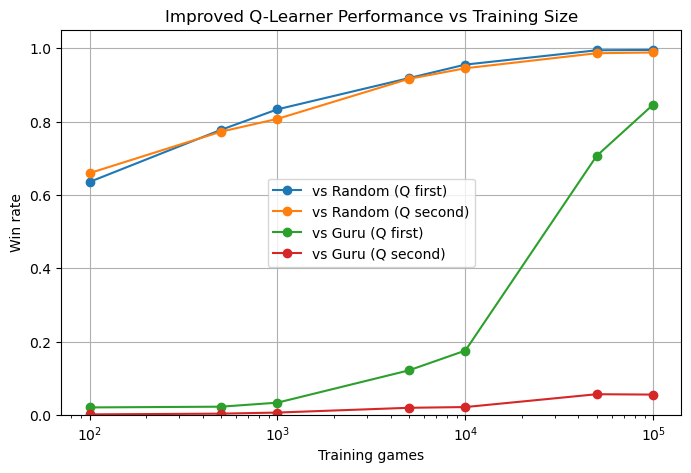

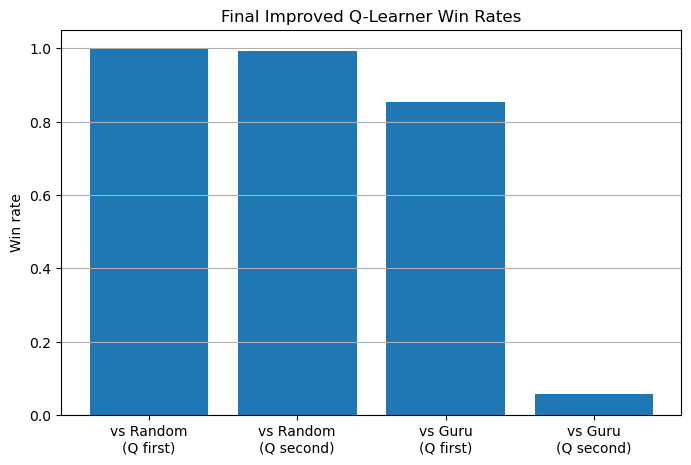

In [2]:
import matplotlib.pyplot as plt

# -----------------------------
# Learning curve for improved learner
# -----------------------------
n_train = [100, 500, 1000, 5000, 10000, 50000, 100000]
wins_random_first = []
wins_random_second = []
wins_guru_first = []
wins_guru_second = []

for n in n_train:
    random.seed(1)
    np.random.seed(1)
    
    nim_qlearn_improved(n, guru_prob=0.7)
    
    a1, b1 = play_games_improved(1000, 'QlearnerImproved', 'Random')
    a2, b2 = play_games_improved(1000, 'Random', 'QlearnerImproved')
    a3, b3 = play_games_improved(1000, 'QlearnerImproved', 'Guru')
    a4, b4 = play_games_improved(1000, 'Guru', 'QlearnerImproved')
    
    wins_random_first.append(a1 / (a1 + b1))
    wins_random_second.append(b2 / (a2 + b2))
    wins_guru_first.append(a3 / (a3 + b3))
    wins_guru_second.append(b4 / (a4 + b4))

plt.figure(figsize=(8, 5))
plt.plot(n_train, wins_random_first, marker='o', label='vs Random (Q first)')
plt.plot(n_train, wins_random_second, marker='o', label='vs Random (Q second)')
plt.plot(n_train, wins_guru_first, marker='o', label='vs Guru (Q first)')
plt.plot(n_train, wins_guru_second, marker='o', label='vs Guru (Q second)')
plt.xscale('log')
plt.xlabel('Training games')
plt.ylabel('Win rate')
plt.title('Improved Q-Learner Performance vs Training Size')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

labels = [
    'vs Random\n(Q first)',
    'vs Random\n(Q second)',
    'vs Guru\n(Q first)',
    'vs Guru\n(Q second)'
]

win_rates = [
    4986 / 5000,
    4963 / 5000,
    4267 / 5000,
    289 / 5000
]

plt.figure(figsize=(8, 5))
plt.bar(labels, win_rates)
plt.ylabel('Win rate')
plt.title('Final Improved Q-Learner Win Rates')
plt.ylim(0, 1.05)
plt.grid(True, axis='y')
plt.show()



#### Plot Interpretation

The learning curve demonstrates how the improved Q-learner's performance evolves with increasing training data. Against the Random player, the model rapidly converges to near-optimal performance, reaching close to 100% win rates in both turn orders. This indicates that the agent successfully learns an optimal policy in a relatively simple environment.

Against the Guru player, performance improves more gradually. When moving first, the Q-learner shows a sharp increase in win rate after approximately 10,000 training games, suggesting that it begins to discover strong strategies that approximate optimal play. However, when moving second, performance remains low throughout training, indicating that the agent is unable to overcome the inherent disadvantage of the second player in Nim under optimal play.

The final performance plot reinforces these findings, showing near-perfect play against the Random opponent and strong but imperfect performance against the Guru when moving first. The asymmetry between first and second player outcomes highlights the importance of game structure in reinforcement learning performance.

Overall, these plots demonstrate that the improved Q-learning model not only achieves strong final performance but also converges in a stable and interpretable manner over time.

#### Results

Performance was evaluated over 5000 games for each matchup:

- **QlearnerImproved vs Random**: 4986 wins / 14 losses (~99.7%)
- **Random vs QlearnerImproved**: 37 wins / 4963 losses (~99.3%)

- **QlearnerImproved vs Guru**: 4267 wins / 733 losses (~85.3%)
- **Guru vs QlearnerImproved**: 4711 wins / 289 losses (~5.8%)

For comparison, the baseline Q-learner from the course notebook achieves approximately **~72–75% win rate against the Random player**, indicating a substantial improvement in performance with the modified approach.


#### Interpretation

The improved Q-learner achieves near-optimal performance against the Random player in both turn orders, demonstrating that it has effectively learned a strong policy for the Nim environment. Compared to the baseline model, the large increase in win rate reflects the benefit of incorporating both **loss penalties** and **future reward estimation**, which provide more informative feedback during training.

Against the Guru player, the model performs strongly when moving first (~85.3% win rate), but struggles when moving second (~5.8%). This asymmetry reflects the inherent first-move advantage in Nim under optimal play, where a player starting from a winning state can force a victory with correct strategy.

The performance gains can be directly attributed to the improvements made to the learning process. Penalizing losses propagates negative value backward through prior states, helping the agent avoid sequences of actions that lead to defeat. Additionally, the Bellman-style Q-learning update enables the agent to evaluate actions based on both immediate and future rewards, resulting in a more effective long-term strategy.

Overall, these results demonstrate that the improved Q-learning model learns a significantly stronger policy than the baseline implementation and is capable of approaching optimal play under favorable conditions.

#### References


Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.